# ML Mini Project – Phase 2
## Predicting and Classifying Air Quality Index (AQI) Using Machine Learning

**Group size:** 2 students  
**Dataset:** `air_quality_dataset.csv` (the supplied Phase 1 dataset; filename variants are also detected automatically)

This notebook implements exactly the **six models declared in Phase 1**:
- **Regression:** Multiple Linear Regression, KNN Regressor, Random Forest Regressor *(ensemble)*
- **Classification:** Logistic Regression, Decision Tree Classifier, Random Forest Classifier *(ensemble)*

This gives **2 ensemble models and 4 other models**. The numerical AQI target is evaluated using MAE, MSE, RMSE and R². AQI-category prediction is evaluated using accuracy, macro-F1, precision, recall and confusion matrices.


## 1. Import libraries

In [9]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 2. Load and inspect the actual dataset

In [27]:
from pathlib import Path
dataset_path = Path("air_quality_dataset.csv")

if not dataset_path.exists():
    raise FileNotFoundError(
        "Place air_quality_dataset.csv in the same folder as this notebook."
    )

df = pd.read_csv(dataset_path)

print("Loaded dataset:", dataset_path.name)

# Convert measurement columns to numeric values
measurement_columns = [
    "AQI", "PM2.5", "PM10", "Ozone", "NO2", "CO", "SO2",
    "Temperature", "Humidity"
]

for column in measurement_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Dataset shape:", df.shape)

display(df.head())
df.info()
display(df.describe(include="all").T)

Loaded dataset: air_quality_dataset.csv
Dataset shape: (5583, 11)


,Date,City,AQI,PM2.5,PM10,Ozone,NO2,CO,SO2,Temperature,Humidity
0,2024-10-16,Los Angeles,128.0,28.78,68.84,58.29,57.56,2.781,17.10,3.4,82.2
1,2023-01-26,Jacksonville,111.0,28.73,61.93,59.00,35.73,1.810,16.33,17.0,36.0
2,2023-10-09,Houston,91.0,20.04,47.10,66.20,43.91,2.566,15.27,1.0,68.6
3,2023-08-17,Chicago,108.0,23.39,47.90,62.85,48.89,2.332,18.49,9.4,85.7
4,2023-04-15,Austin,106.0,26.51,56.08,62.38,NaN,1.867,15.93,17.3,48.7


<class 'pandas.DataFrame'>
RangeIndex: 5583 entries, 0 to 5582
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         5583 non-null   str    
 1   City         5583 non-null   str    
 2   AQI          5472 non-null   float64
 3   PM2.5        5486 non-null   float64
 4   PM10         5523 non-null   float64
 5   Ozone        5508 non-null   float64
 6   NO2          5490 non-null   float64
 7   CO           5421 non-null   float64
 8   SO2          5454 non-null   float64
 9   Temperature  5435 non-null   float64
 10  Humidity     5479 non-null   float64
dtypes: float64(9), str(2)
memory usage: 582.2 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,5583,730,2024-12-02,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,5583,15,San Diego,391,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AQI,5472.0,NaN,NaN,NaN,111.969664,24.152583,46.0,96.0,110.0,126.0,497.0
PM2.5,5486.0,NaN,NaN,NaN,26.271325,11.771521,9.21,22.67,25.63,29.07,461.33
PM10,5523.0,NaN,NaN,NaN,56.925913,15.61923,20.49,48.32,55.89,64.59,448.64
Ozone,5508.0,NaN,NaN,NaN,65.779486,16.065461,28.35,54.33,62.99,75.2525,283.97
NO2,5490.0,NaN,NaN,NaN,43.07198,11.077596,22.39,38.15,42.64,47.27,400.99
CO,5421.0,NaN,NaN,NaN,2.167954,1.027549,0.722,1.849,2.134,2.424,47.281
SO2,5454.0,NaN,NaN,NaN,15.829078,8.49065,0.0,12.97,15.55,18.1975,290.76
Temperature,5435.0,NaN,NaN,NaN,14.848556,11.801714,-19.7,5.0,14.6,24.8,53.5


In [14]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nExact duplicate rows:", df.duplicated().sum())
print("\nNumber of cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Column names:
['Date', 'City', 'AQI', 'PM2.5', 'PM10', 'Ozone', 'NO2', 'CO', 'SO2', 'Temperature', 'Humidity']

Missing values by column:


,Missing values
Date,0
City,0
AQI,111
PM2.5,97
PM10,60
Ozone,75
NO2,93
CO,162
SO2,129
Temperature,148



Exact duplicate rows: 86

Number of cities: 15
Date range: 2023-01-01 to 2024-12-30


## 3. Exploratory Data Analysis (EDA)

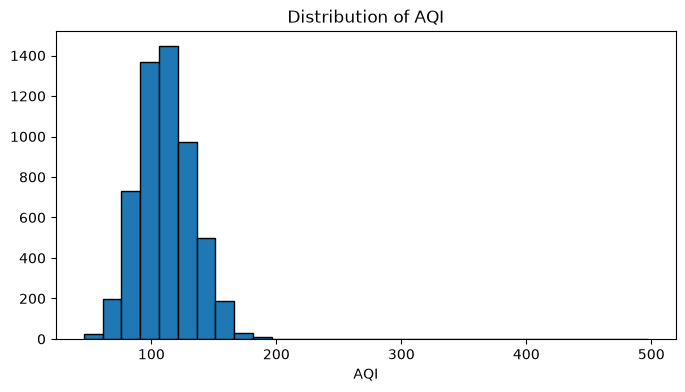

,count,mean,median,min,max
City,,,,,
Los Angeles,385,136.303896,135.0,80.0,196.0
Houston,355,129.087324,129.0,63.0,401.0
Phoenix,347,125.463977,126.0,80.0,178.0
Dallas,355,118.312676,118.0,55.0,371.0
Chicago,351,117.994302,117.0,74.0,174.0
Philadelphia,355,113.797183,113.0,57.0,169.0
New York,346,113.179191,113.0,55.0,165.0
Fort Worth,365,112.221918,111.0,67.0,337.0
San Antonio,377,107.169761,107.0,63.0,161.0


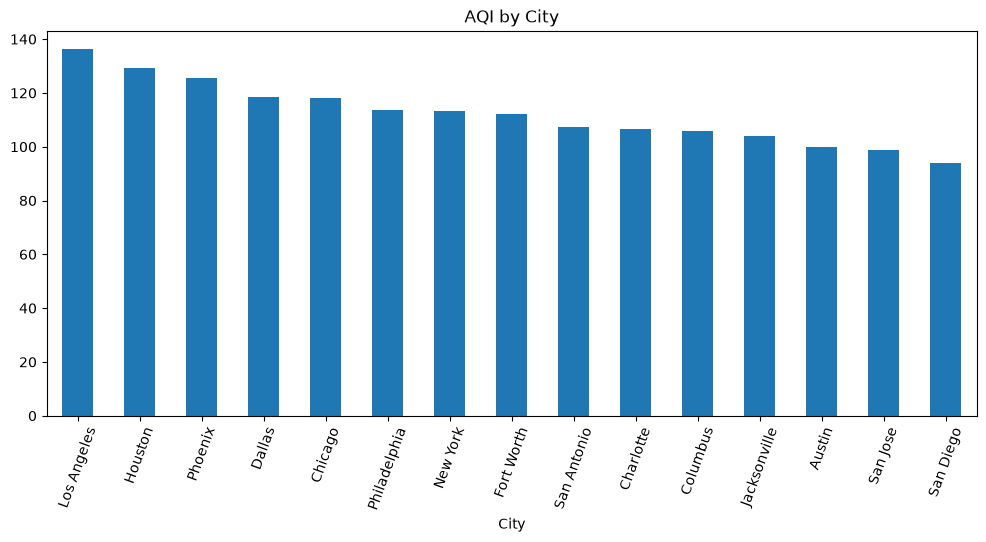

In [15]:
# AQI distribution
plt.figure(figsize=(8, 4))
plt.hist(df["AQI"].dropna(), bins=30, edgecolor="black")
plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.show()

# AQI summary by city
city_summary = df.groupby("City")["AQI"].agg(["count", "mean", "median", "min", "max"]).sort_values("mean", ascending=False)
display(city_summary)

plt.figure(figsize=(12, 5))
df.groupby("City")["AQI"].mean().sort_values(ascending=False).plot(kind="bar")
plt.xticks(rotation=70)
plt.title("AQI by City")
plt.show()

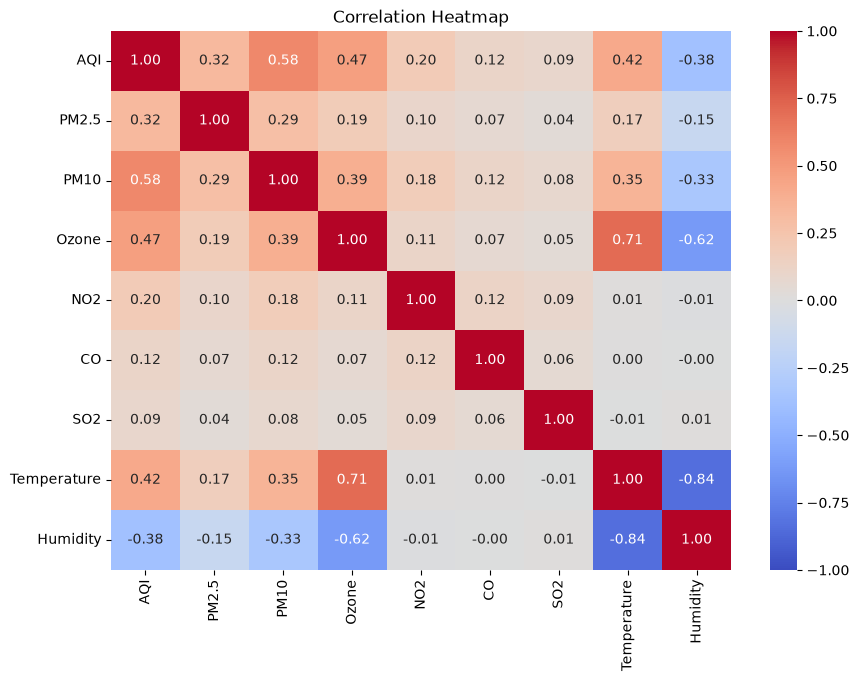

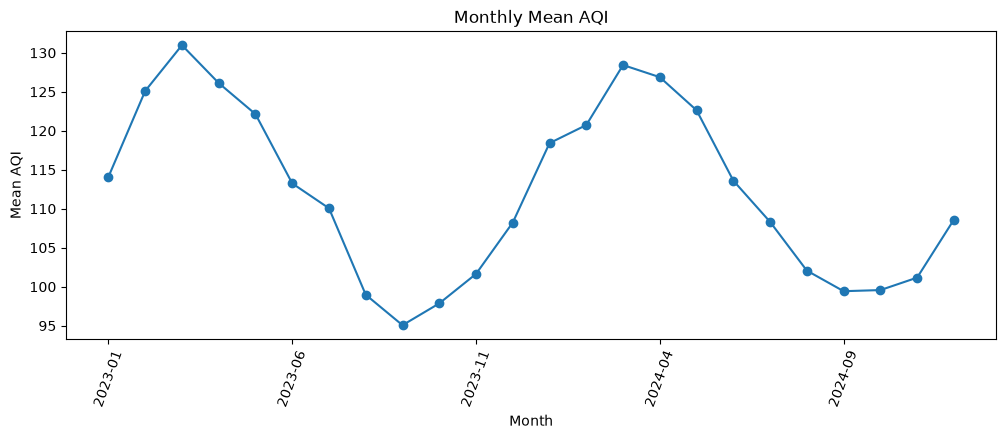

In [16]:
numeric_cols_for_corr = [
    "AQI", "PM2.5", "PM10", "Ozone", "NO2", "CO", "SO2",
    "Temperature", "Humidity"
]
plt.figure(figsize=(10, 7))
corr_matrix = df[numeric_cols_for_corr].corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar=True)
plt.title("Correlation Heatmap")
plt.show()

# Daily/monthly trend
eda_df = df.copy()
eda_df["Date"] = pd.to_datetime(eda_df["Date"], errors="coerce")
monthly = eda_df.dropna(subset=["Date", "AQI"]).groupby(eda_df["Date"].dt.to_period("M").astype(str))["AQI"].mean()
plt.figure(figsize=(12, 4))
monthly.plot(marker="o")
plt.title("Monthly Mean AQI")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.xticks(rotation=70)
plt.show()

## 4. Clean data and create AQI categories

The Phase 1 breakpoints are preserved:

- 0–50: Good
- 51–100: Moderate
- 101–150: Unhealthy (Sensitive)
- 151–200: Unhealthy
- 201–300: Very Unhealthy
- Above 300: Hazardous

Missing target values are removed rather than imputed. Predictor imputation, scaling and encoding are placed inside pipelines so they are fitted on training data only.

In [17]:
CATEGORY_ORDER = [
    "Good", "Moderate", "Unhealthy (Sensitive)",
    "Unhealthy", "Very Unhealthy", "Hazardous"
]

def categorize_aqi(aqi):
    if pd.isna(aqi):
        return np.nan
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Moderate"
    elif aqi <= 150:
        return "Unhealthy (Sensitive)"
    elif aqi <= 200:
        return "Unhealthy"
    elif aqi <= 300:
        return "Very Unhealthy"
    else:
        return "Hazardous"

data = df.drop_duplicates().copy()
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data = data.dropna(subset=["AQI", "Date"]).copy()

data["Month"] = data["Date"].dt.month
data["DayOfWeek"] = data["Date"].dt.dayofweek

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    return "Fall"

data["Season"] = data["Month"].apply(get_season)
data["AQI_Category"] = data["AQI"].apply(categorize_aqi)

print("Original rows:", len(df))
print("Rows after duplicate removal and dropping missing target/date:", len(data))
print("\nAQI category counts:")
display(data["AQI_Category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0).to_frame("Count"))

Original rows: 5583
Rows after duplicate removal and dropping missing target/date: 5387

AQI category counts:


,Count
AQI_Category,
Good,5
Moderate,1726
Unhealthy (Sensitive),3404
Unhealthy,245
Very Unhealthy,0
Hazardous,7


### Important class imbalance note
If a category has no records, the model cannot learn that category from this dataset. Keep the six original labels in the report and do not create fake records. The small number of examples in rare categories also makes their precision, recall and F1-scores less stable.

## 5. Define features and split the data

In [18]:
# AQI and AQI_Category are targets only; they are not predictors.
numeric_features = [
    "PM2.5", "PM10", "Ozone", "NO2", "CO", "SO2",
    "Temperature", "Humidity", "Month", "DayOfWeek"
]
categorical_features = ["City", "Season"]
feature_columns = numeric_features + categorical_features

X = data[feature_columns].copy()
y_reg = data["AQI"].astype(float)
y_clf = data["AQI_Category"].astype(str)

# Stratify by category to preserve class proportions where possible.
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_clf
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 4309
Testing rows: 1078


In [19]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

## 6. Regression models

The three regression models below match the Phase 1 shortlist exactly. **Random Forest Regressor is the regression ensemble model.**

In [20]:
regression_models = {
    "Multiple Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Random Forest Regressor (Ensemble)": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    )
}

regression_results = []
regression_predictions = {}
trained_regression_pipelines = {}

for name, model in regression_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_reg_train)
    predictions = pipe.predict(X_test)
    trained_regression_pipelines[name] = pipe
    regression_predictions[name] = predictions
    mse = mean_squared_error(y_reg_test, predictions)
    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_reg_test, predictions)
    })

regression_results_df = pd.DataFrame(regression_results).sort_values("RMSE")
display(regression_results_df.round(4))

print("Best regression model by lowest RMSE:", regression_results_df.iloc[0]["Model"])


,Model,MAE,MSE,RMSE,R2
2,Random Forest Regressor (Ensemble),8.2468,303.5282,17.4221,0.5448
1,KNN Regressor,10.7152,364.2225,19.0846,0.4537
0,Multiple Linear Regression,10.4419,383.6209,19.5862,0.4246


Best regression model by lowest RMSE: Random Forest Regressor (Ensemble)


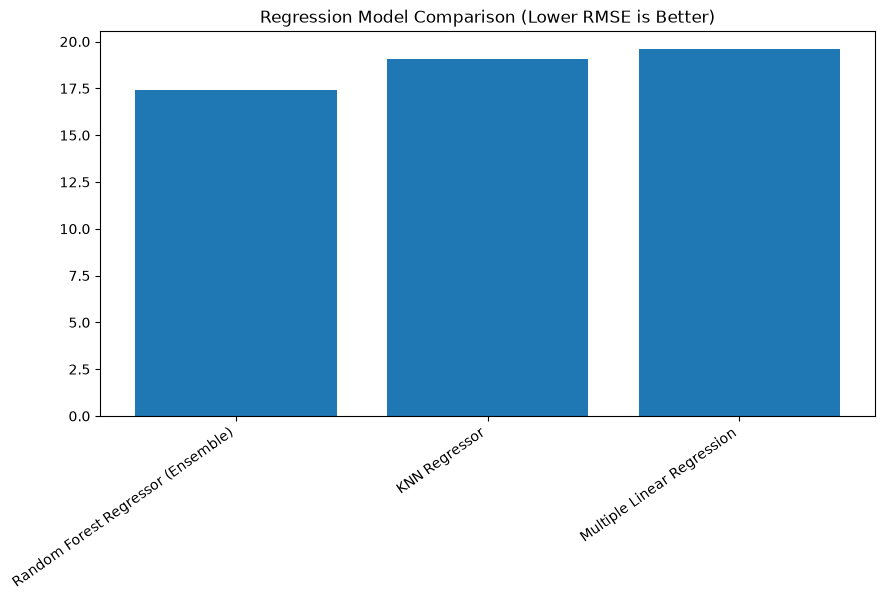

Best regression model by test RMSE: Random Forest Regressor (Ensemble)


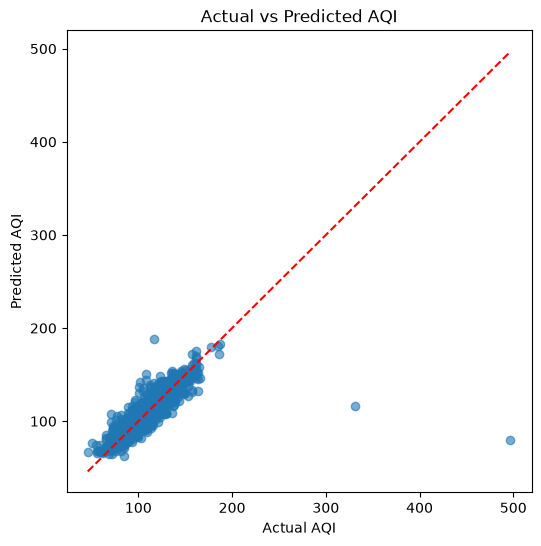

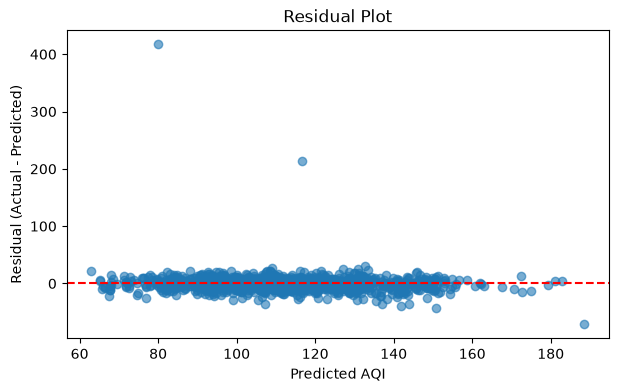

In [21]:
plt.figure(figsize=(10, 5))
plt.bar(regression_results_df["Model"], regression_results_df["RMSE"])
plt.xticks(rotation=35, ha="right")
plt.title("Regression Model Comparison (Lower RMSE is Better)")
plt.show()

best_regression_name = regression_results_df.iloc[0]["Model"]
best_regression_model = trained_regression_pipelines[best_regression_name]
best_regression_predictions = regression_predictions[best_regression_name]

print("Best regression model by test RMSE:", best_regression_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, best_regression_predictions, alpha=0.6)
low = min(y_reg_test.min(), best_regression_predictions.min())
high = max(y_reg_test.max(), best_regression_predictions.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")
plt.show()

residuals = y_reg_test.to_numpy() - best_regression_predictions
plt.figure(figsize=(7, 4))
plt.scatter(best_regression_predictions, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted AQI")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

## 7. Classification models

The three classifiers below match the Phase 1 shortlist exactly. **Random Forest Classifier is the classification ensemble model.** Because the AQI categories are imbalanced, compare models using macro-F1 and inspect the confusion matrix, rather than relying on accuracy alone.

In [22]:
classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree Classifier": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest Classifier (Ensemble)": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

classification_results = []
classification_predictions = {}
trained_classification_pipelines = {}

for name, model in classification_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_clf_train)
    predictions = pipe.predict(X_test)
    trained_classification_pipelines[name] = pipe
    classification_predictions[name] = predictions
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_clf_test, predictions),
        "Macro-F1": f1_score(y_clf_test, predictions, average="macro", zero_division=0),
        "Weighted-F1": f1_score(y_clf_test, predictions, average="weighted", zero_division=0),
        "Macro-Precision": precision_score(y_clf_test, predictions, average="macro", zero_division=0),
        "Macro-Recall": recall_score(y_clf_test, predictions, average="macro", zero_division=0)
    })

classification_results_df = pd.DataFrame(classification_results).sort_values(
    "Macro-F1", ascending=False
)
display(classification_results_df.round(4))

print("Best classification model by highest Macro-F1:", classification_results_df.iloc[0]["Model"])


,Model,Accuracy,Macro-F1,Weighted-F1,Macro-Precision,Macro-Recall
2,Random Forest Classifier (Ensemble),0.8024,0.4412,0.8056,0.4205,0.4760
1,Decision Tree Classifier,0.7755,0.4018,0.7753,0.4019,0.4018
0,Logistic Regression,0.6373,0.3877,0.6769,0.3728,0.6239


Best classification model by highest Macro-F1: Random Forest Classifier (Ensemble)


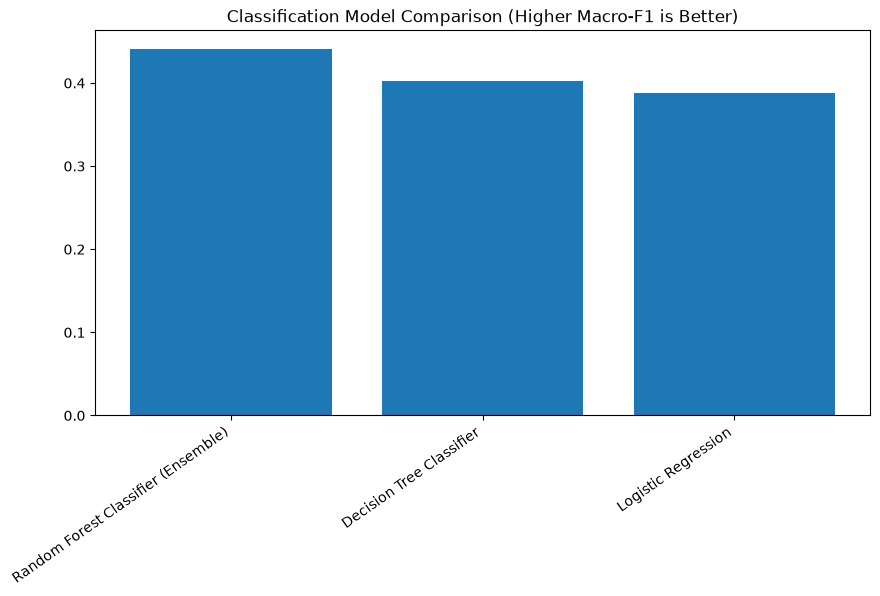

Best classification model by test Macro-F1: Random Forest Classifier (Ensemble)


In [23]:
plt.figure(figsize=(10, 5))
plt.bar(classification_results_df["Model"], classification_results_df["Macro-F1"])
plt.xticks(rotation=35, ha="right")
plt.title("Classification Model Comparison (Higher Macro-F1 is Better)")
plt.show()

best_classification_name = classification_results_df.iloc[0]["Model"]
best_classification_model = trained_classification_pipelines[best_classification_name]
best_classification_predictions = classification_predictions[best_classification_name]
print("Best classification model by test Macro-F1:", best_classification_name)


Logistic Regression
                       precision    recall  f1-score   support

                 Good       0.08      1.00      0.15         1
             Moderate       0.66      0.72      0.69       345
Unhealthy (Sensitive)       0.86      0.58      0.69       681
            Unhealthy       0.27      0.82      0.40        49
       Very Unhealthy       0.00      0.00      0.00         0
            Hazardous       0.00      0.00      0.00         2

             accuracy                           0.64      1078
            macro avg       0.31      0.52      0.32      1078
         weighted avg       0.76      0.64      0.68      1078



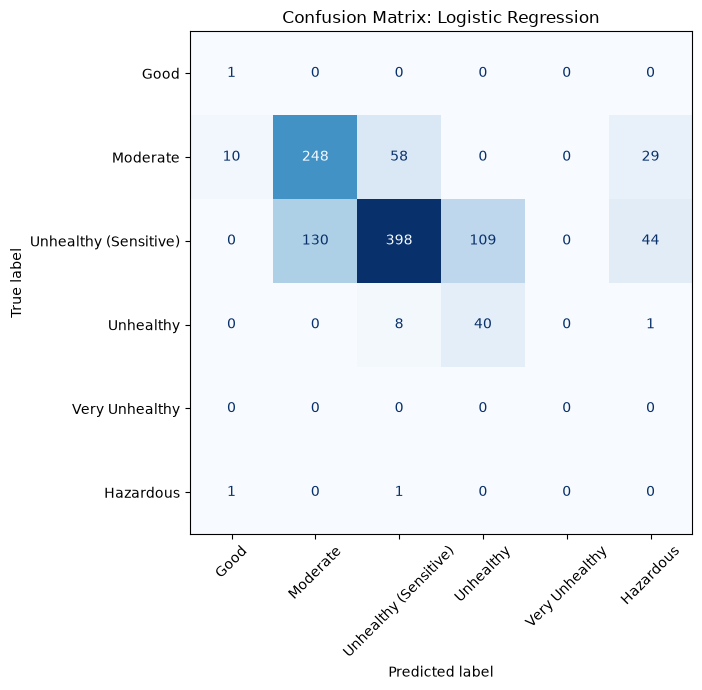


Decision Tree Classifier
                       precision    recall  f1-score   support

                 Good       0.00      0.00      0.00         1
             Moderate       0.72      0.74      0.73       345
Unhealthy (Sensitive)       0.83      0.82      0.82       681
            Unhealthy       0.46      0.45      0.45        49
       Very Unhealthy       0.00      0.00      0.00         0
            Hazardous       0.00      0.00      0.00         2

             accuracy                           0.78      1078
            macro avg       0.33      0.33      0.33      1078
         weighted avg       0.78      0.78      0.78      1078



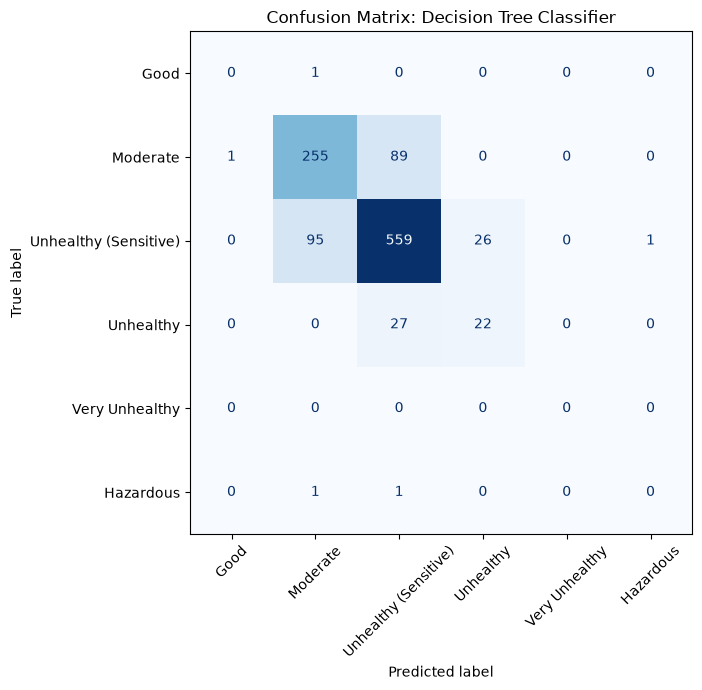


Random Forest Classifier (Ensemble)
                       precision    recall  f1-score   support

                 Good       0.00      0.00      0.00         1
             Moderate       0.74      0.83      0.78       345
Unhealthy (Sensitive)       0.88      0.80      0.84       681
            Unhealthy       0.48      0.76      0.59        49
       Very Unhealthy       0.00      0.00      0.00         0
            Hazardous       0.00      0.00      0.00         2

             accuracy                           0.80      1078
            macro avg       0.35      0.40      0.37      1078
         weighted avg       0.82      0.80      0.81      1078



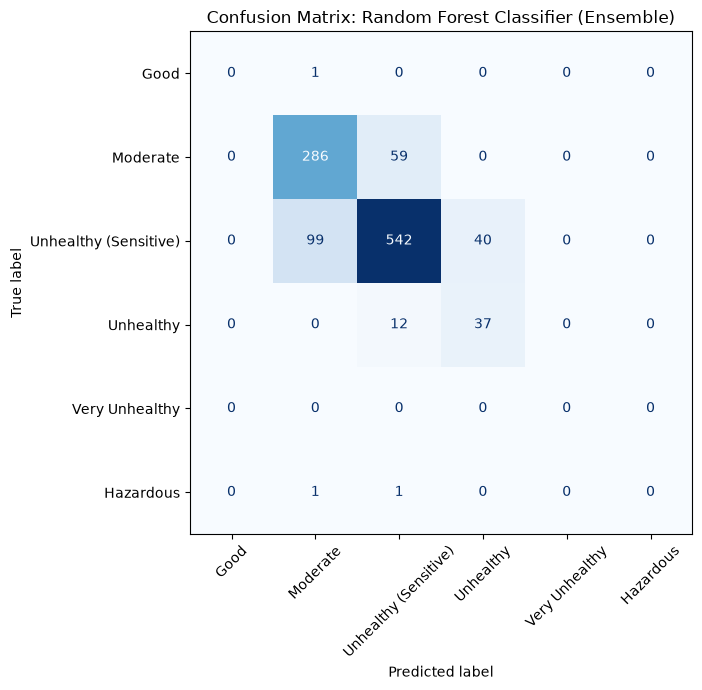

In [24]:
# Detailed per-class precision, recall and F1 for every classifier.
for name, predictions in classification_predictions.items():
    print("\n" + "=" * 80)
    print(name)
    print(classification_report(
        y_clf_test,
        predictions,
        labels=CATEGORY_ORDER,
        zero_division=0
    ))

    cm = confusion_matrix(y_clf_test, predictions, labels=CATEGORY_ORDER)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CATEGORY_ORDER)
    fig, ax = plt.subplots(figsize=(9, 7))
    disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
    plt.title(f"Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

## 8. Feature importance for Random Forest

,Feature,Importance
0,numeric__PM2.5,0.643530
1,numeric__PM10,0.092452
2,numeric__Ozone,0.068587
5,numeric__SO2,0.057185
4,numeric__CO,0.024645
7,numeric__Humidity,0.022877
6,numeric__Temperature,0.020555
3,numeric__NO2,0.016582
9,numeric__DayOfWeek,0.012095
8,numeric__Month,0.009547


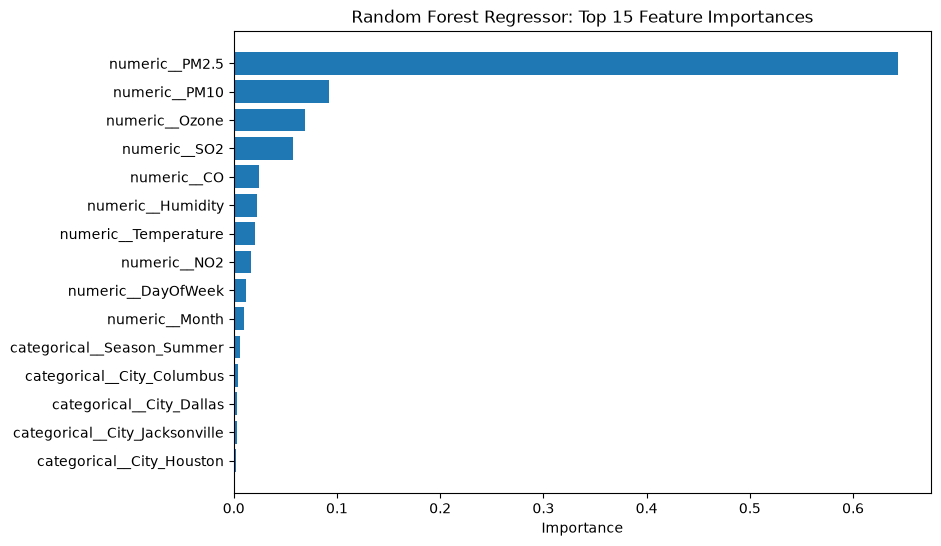

In [25]:
rf_name = "Random Forest Regressor (Ensemble)"
rf_pipeline = trained_regression_pipelines[rf_name]
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(feature_importance_df.head(15))
plt.figure(figsize=(9, 6))
top_features = feature_importance_df.head(15).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Random Forest Regressor: Top 15 Feature Importances")
plt.xlabel("Importance")
plt.show()

## 9. Save comparison tables and trained models

In [26]:
from pathlib import Path
import joblib

output_dir = Path("outputs")
model_dir = Path("models")
output_dir.mkdir(exist_ok=True)
model_dir.mkdir(exist_ok=True)

regression_results_df.to_csv(output_dir / "regression_metrics.csv", index=False)
classification_results_df.to_csv(output_dir / "classification_metrics.csv", index=False)
feature_importance_df.to_csv(output_dir / "random_forest_feature_importance.csv", index=False)

for name, pipe in trained_regression_pipelines.items():
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(pipe, model_dir / f"{safe_name}.joblib")

for name, pipe in trained_classification_pipelines.items():
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(pipe, model_dir / f"{safe_name}.joblib")

print("Saved metric tables to outputs/ and trained pipelines to models/.")

Saved metric tables to outputs/ and trained pipelines to models/.


## 10. Findings and limitations

Use the printed test metrics to identify the best model. Do not choose a model before measuring its performance.

- Regression: compare MAE, MSE, RMSE and R². Lower error is better; higher R² is generally better.
- Classification: compare macro-F1, weighted-F1, precision, recall and confusion matrices. Macro-F1 is important when classes are imbalanced.
- The dataset has rare AQI classes, and a class with zero examples cannot be learned by a supervised classifier.
- Since AQI is derived from pollutants, this is an AQI estimation experiment, not evidence of future forecasting.
- Results may not generalize to other cities, measurement systems or time periods.